# CineXplain: Metadata Exploration (Member 1)

This notebook explores and cleans the movie metadata used by the content-based recommender.

**Questions it answers**
1. What does the raw MovieLens metadata look like, and what is missing?
2. What does cleaning do (year extraction, title cleaning, genres)?
3. How much of the catalog did TMDB enrichment fill in (plot, cast, franchise)?
4. What final text does each movie turn into for TF-IDF and for embeddings?
5. (Optional) What does the ratings data look like?

**Requires:** `data/movies.csv`. Optional: `data/movies_enriched.csv`, `data/ratings.csv`.
Plots need `matplotlib` (`pip install matplotlib jupyter`).

In [2]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Find the project root whether the notebook is run from notebooks/ or from the root
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.content_recommender import (ContentRecommender, load_movies,
                                     DEFAULT_MOVIES, DEFAULT_ENRICHED)

pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False,
                     "axes.spines.right": False})
print("Project root:", ROOT)

Project root: /home/mounika/cineXplain


## 1. Raw MovieLens metadata

In [3]:
raw = pd.read_csv(DEFAULT_MOVIES)
print("Rows:", len(raw))
print("Columns:", list(raw.columns))
raw.head(10)

Rows: 27278
Columns: ['movieId', 'title', 'genres']


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy
5,6,Heat (1995),Action|Crime|Thriller
6,7,Sabrina (1995),Comedy|Romance
7,8,Tom and Huck (1995),Adventure|Children
8,9,Sudden Death (1995),Action
9,10,GoldenEye (1995),Action|Adventure|Thriller


In [4]:
raw_report = pd.Series({
    "rows": len(raw),
    "unique movieIds": raw["movieId"].nunique(),
    "duplicate movieIds": int(raw["movieId"].duplicated().sum()),
    "missing title": int(raw["title"].isna().sum()),
    "missing genres (NaN)": int(raw["genres"].isna().sum()),
    '"(no genres listed)"': int((raw["genres"] == "(no genres listed)").sum()),
    "titles without a (YYYY) year": int((~raw["title"].astype(str).str.contains(r"\(\d{4}\)\s*$")).sum()),
}, name="count")
raw_report.to_frame()

,count
rows,27278
unique movieIds,27278
duplicate movieIds,0
missing title,0
missing genres (NaN),0
"""(no genres listed)""",246
titles without a (YYYY) year,23


## 2. After cleaning (`load_movies()`)

Cleaning does the following:
- removes duplicate `movieId` rows,
- extracts `year` from titles like `Toy Story (1995)`,
- creates `clean_title` without the year,
- turns missing or `(no genres listed)` genres into an empty string,
- merges the TMDB columns `overview`, `cast` and `collection` if `data/movies_enriched.csv` exists.

In [5]:
# Load WITHOUT enrichment first, to see only the effect of cleaning
movies_plain = load_movies(enriched_path=None)
movies_plain[["movieId", "title", "clean_title", "year", "genres"]].head(8)

,movieId,title,clean_title,year,genres
0,1,Toy Story (1995),Toy Story,1995.0,Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Jumanji,1995.0,Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Grumpier Old Men,1995.0,Comedy|Romance
3,4,Waiting to Exhale (1995),Waiting to Exhale,1995.0,Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Father of the Bride Part II,1995.0,Comedy
5,6,Heat (1995),Heat,1995.0,Action|Crime|Thriller
6,7,Sabrina (1995),Sabrina,1995.0,Comedy|Romance
7,8,Tom and Huck (1995),Tom and Huck,1995.0,Adventure|Children


In [6]:
clean_report = pd.Series({
    "movies after cleaning": len(movies_plain),
    "missing year": int(movies_plain["year"].isna().sum()),
    "empty genres": int((movies_plain["genres"] == "").sum()),
    "year range": f"{int(movies_plain['year'].min())} to {int(movies_plain['year'].max())}",
}, name="value")
clean_report.to_frame()

,value
movies after cleaning,27278
missing year,23
empty genres,246
year range,1891 to 2015


### Genres

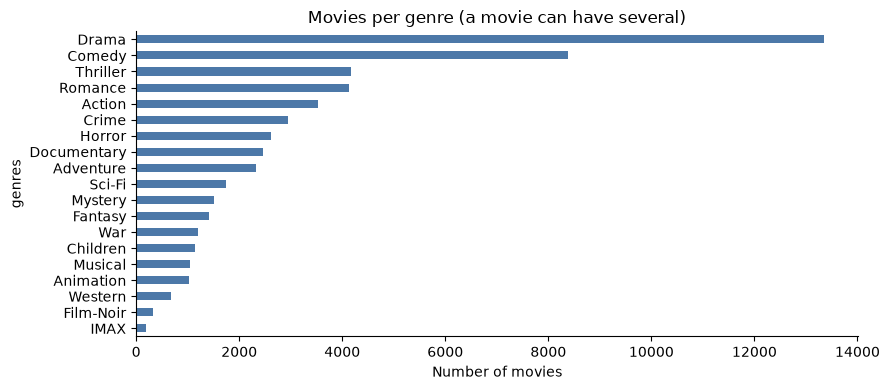

Distinct genres: 19


In [7]:
genre_lists = movies_plain["genres"].map(lambda g: [x for x in g.split("|") if x])
genre_counts = genre_lists.explode().value_counts()

ax = genre_counts.sort_values().plot.barh(color="#4c78a8")
ax.set_title("Movies per genre (a movie can have several)")
ax.set_xlabel("Number of movies")
plt.tight_layout(); plt.show()

print("Distinct genres:", len(genre_counts))

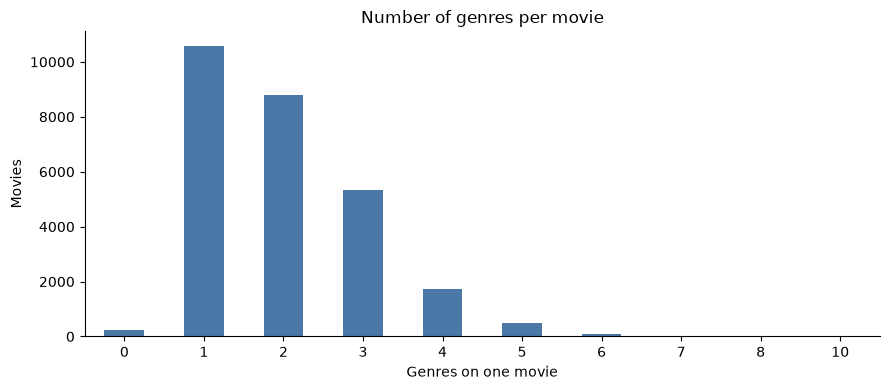

Average genres per movie: 1.99


In [8]:
n_genres = genre_lists.map(len)
ax = n_genres.value_counts().sort_index().plot.bar(color="#4c78a8", rot=0)
ax.set_title("Number of genres per movie")
ax.set_xlabel("Genres on one movie"); ax.set_ylabel("Movies")
plt.tight_layout(); plt.show()
print(f"Average genres per movie: {n_genres.mean():.2f}")

### Release years

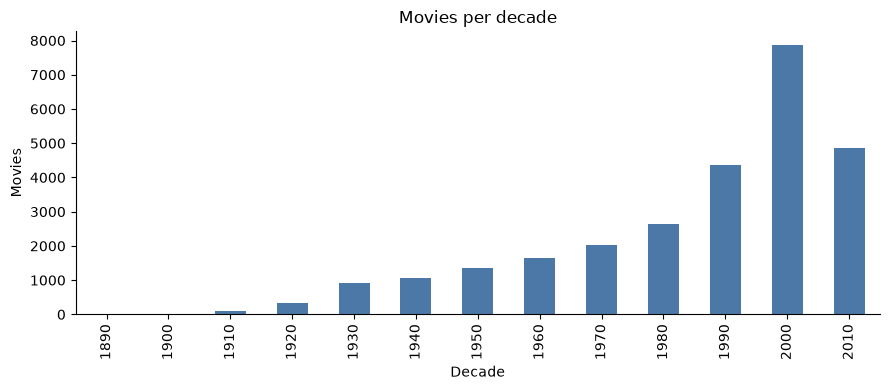

In [9]:
decade = (movies_plain["year"] // 10 * 10).dropna().astype(int)
ax = decade.value_counts().sort_index().plot.bar(color="#4c78a8")
ax.set_title("Movies per decade")
ax.set_xlabel("Decade"); ax.set_ylabel("Movies")
plt.tight_layout(); plt.show()

## 3. TMDB enrichment coverage

MovieLens has no plot or cast. `scripts/enrich_metadata.py` adds `overview`, `cast` and `collection`.
This section checks how complete that data is.

In [10]:
movies = load_movies()   # now includes the enriched columns if the file exists
has_enriched = DEFAULT_ENRICHED.exists()
print("Enriched file found:", has_enriched)

if has_enriched:
    cov = pd.DataFrame({
        "movies with value": [
            int((movies["overview"] != "").sum()),
            int((movies["cast"] != "").sum()),
            int((movies["collection"] != "").sum()),
        ],
    }, index=["overview (plot)", "cast", "collection (franchise)"])
    cov["% of catalog"] = (cov["movies with value"] / len(movies) * 100).round(1)
    display(cov)
else:
    print("Run scripts/enrich_metadata.py to create data/movies_enriched.csv, then re-run this notebook.")

Enriched file found: True


,movies with value,% of catalog
overview (plot),26620,97.6
cast,26200,96.0
collection (franchise),3802,13.9


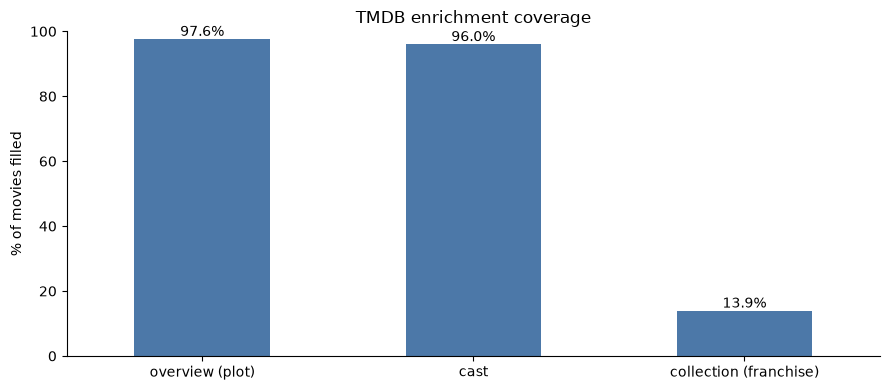

In [11]:
if has_enriched:
    ax = cov["% of catalog"].plot.bar(color="#4c78a8", rot=0)
    ax.set_ylim(0, 100); ax.set_ylabel("% of movies filled")
    ax.set_title("TMDB enrichment coverage")
    for i, v in enumerate(cov["% of catalog"]):
        ax.text(i, v + 1, f"{v}%", ha="center")
    plt.tight_layout(); plt.show()

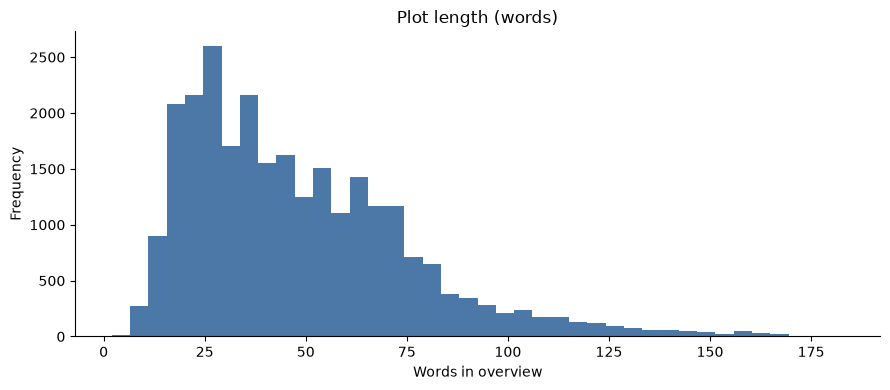

Median plot length: 42 words


In [12]:
if has_enriched:
    words = movies.loc[movies["overview"] != "", "overview"].str.split().map(len)
    ax = words.plot.hist(bins=40, color="#4c78a8")
    ax.set_title("Plot length (words)"); ax.set_xlabel("Words in overview")
    plt.tight_layout(); plt.show()
    print(f"Median plot length: {int(words.median())} words")

In [13]:
if has_enriched:
    # Franchises with the most movies: this is what the sequel detection (Member 5) will use
    top = (movies.loc[movies["collection"] != "", "collection"]
                 .value_counts().head(10))
    top.to_frame("movies")

## 4. What each movie becomes: the text documents

The recommender turns every movie into text first. TF-IDF and the embedding model both read this text.

In [14]:
rec = ContentRecommender(movies)     # builds the texts only, no model needed
rec.search_title("Toy Story (1995)")

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy


In [15]:
idx = rec.id_to_idx[1]               # movieId 1 = Toy Story (1995)
print("TF-IDF document:\n", rec.tfidf_texts[idx][:600], "\n")
print("Embedding document:\n", rec.embedding_texts[idx][:600])

TF-IDF document:
 adventure animation children comedy fantasy adventure animation children comedy fantasy tomhanks timallen donrickles jimvarney wallaceshawn decade1990 toy story led by woody andy s toys live happily in his room until andy s birthday brings buzz lightyear onto the scene afraid of losing his place in andy s heart woody plots against buzz but when circumstances separate buzz and woody from their owner the duo eventually learns to put aside their differences 

Embedding document:
 Toy Story. Genres: Adventure, Animation, Children, Comedy, Fantasy. Cast: Tom Hanks, Tim Allen, Don Rickles, Jim Varney, Wallace Shawn. Plot: Led by Woody, Andy's toys live happily in his room until Andy's birthday brings Buzz Lightyear onto the scene. Afraid of losing his place in Andy's heart, Woody plots against Buzz. But when circumstances separate Buzz and Woody from their owner, the duo eventually learns to put aside their differences.


In [16]:
# Documents that are only title + genres (no plot, no cast) are the weakest.
# They are the ones most likely to get identical vectors.
if has_enriched:
    thin = (movies["overview"] == "") & (movies["cast"] == "")
    print(f"Movies with neither plot nor cast: {int(thin.sum())} ({thin.mean()*100:.1f}%)")

Movies with neither plot nor cast: 648 (2.4%)


## 5. Ratings overview (optional)

Used by `evaluation/content_metrics.py`. "Liked" means a rating of 4 or higher.

20,000,263 ratings | 138,493 users | 26,744 movies rated
Ratings whose movie is in the movie table: 100.0%


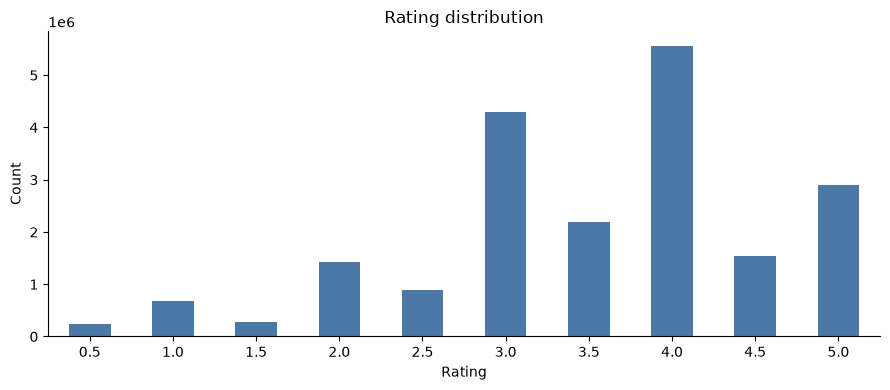

In [17]:
ratings_path = ROOT / "data" / "ratings.csv"
if ratings_path.exists():
    ratings = pd.read_csv(ratings_path)
    print(f"{len(ratings):,} ratings | {ratings['userId'].nunique():,} users | "
          f"{ratings['movieId'].nunique():,} movies rated")
    in_catalog = ratings["movieId"].isin(movies["movieId"]).mean() * 100
    print(f"Ratings whose movie is in the movie table: {in_catalog:.1f}%")

    ax = ratings["rating"].value_counts().sort_index().plot.bar(color="#4c78a8", rot=0)
    ax.set_title("Rating distribution"); ax.set_xlabel("Rating"); ax.set_ylabel("Count")
    plt.tight_layout(); plt.show()
else:
    print("data/ratings.csv not found, skipping.")

In [18]:
if ratings_path.exists():
    per_user = ratings.groupby("userId").size()
    per_movie = ratings.groupby("movieId").size()
    summary = pd.DataFrame({
        "ratings per user": per_user.describe(),
        "ratings per movie": per_movie.describe(),
    }).round(1)
    display(summary)
    print(f"Users with at least 20 ratings (eligible for evaluation): {(per_user >= 20).sum()}")
    print(f"Share of ratings that are 'liked' (>= 4): {(ratings['rating'] >= 4).mean()*100:.1f}%")

,ratings per user,ratings per movie
count,138493.0,26744.0
mean,144.4,747.8
std,230.3,3085.8
min,20.0,1.0
25%,35.0,3.0
50%,68.0,18.0
75%,155.0,205.0
max,9254.0,67310.0


Users with at least 20 ratings (eligible for evaluation): 138493
Share of ratings that are 'liked' (>= 4): 50.0%


## Summary

- Catalog: 27,278 movies, released 1891 to 2015.
- Missing data: 246 movies have no genres, and 23 have no year.
- TMDB enrichment coverage: plot 97.6%, cast 96.0%, collection (franchise) 13.9%. Only 648 movies (2.4%) have neither plot nor cast.
- Main takeaway: the few movies without TMDB data fall back to title and genres only, which weakens both TF-IDF and embeddings for them.